# # 09 · State-space models: Mamba
#
# An SSM keeps a hidden state like an RNN, but is defined by a continuous linear system discretised with a step size Δ:
#
# `h_t = Ā h_{t-1} + B̄ x_t`,  `y_t = C h_t`  with  `Ā = exp(ΔA)`.
#
# **Mamba's insight (selectivity):** make Δ, B and C *functions of the input*, so the model can decide per token what to
# remember or forget (large Δ → "read this", small Δ → "ignore it"). Linear-time, constant memory, no attention at all.

---

### At a glance

| | |
|---|---|
| **Family** | State-space models |
| **Representative models** | S4, Mamba, Mamba-2, Falcon-Mamba |
| **Core idea** | Linear recurrence discretised with an input-dependent step size Δ (selectivity). |
| **Compute / memory** | O(T) time, O(1) inference state |
| **Dataset** | tiny-Shakespeare (char level) – see notebook 00 |
| **Runtime** | ≈ 710 s on a laptop CPU |

### What you will learn

- Implement a selective SSM (Mamba) block
- See how Δ reacts to the input
- Compare inference memory and measured speed with attention

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import time
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np
from llmarch import *
setup_style()
from llmarch.blocks import *
set_seed(0); device = get_device(); STEPS = 800
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]

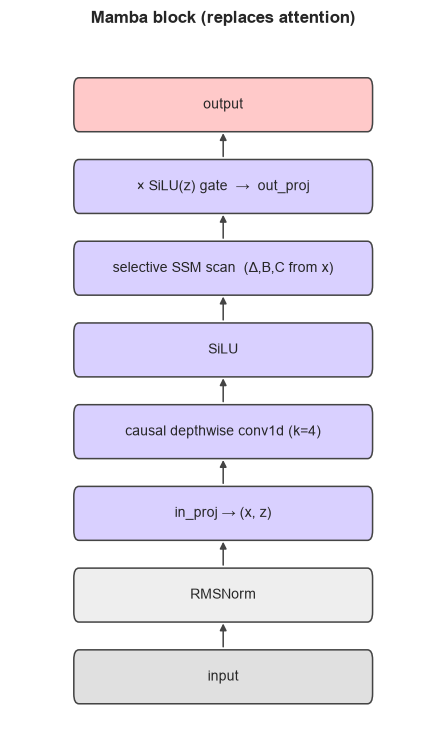

In [2]:
block_diagram([("output", "out"), ("× SiLU(z) gate  →  out_proj", "ssm"), ("selective SSM scan  (Δ,B,C from x)", "ssm"), ("SiLU", "ssm"), ("causal depthwise conv1d (k=4)", "ssm"),
               ("in_proj → (x, z)", "ssm"), ("RMSNorm", "norm"), ("input", "other")][::-1], title="Mamba block (replaces attention)")

# ## The block (pure PyTorch, sequential scan)
# The python `for t in range(T)` loop is the *exact* recurrence. Real Mamba uses a fused parallel-scan CUDA kernel.

In [3]:
show_source(MambaBlock)

```python
class MambaBlock(nn.Module):
    """Simplified Mamba: in_proj -> causal depthwise conv -> selective SSM (input-dependent dt, B, C) -> gate -> out_proj.
    The scan is a plain python loop over time: slow but crystal clear."""
    def __init__(self, d, d_state=16, expand=2, d_conv=4):
        super().__init__()
        self.di, self.N = expand * d, d_state
        self.in_proj = nn.Linear(d, 2 * self.di, bias=False)
        self.conv = nn.Conv1d(self.di, self.di, d_conv, groups=self.di, padding=d_conv - 1)
        self.x_proj = nn.Linear(self.di, 1 + 2 * d_state, bias=False)     # -> dt (rank 1 broadcast), B, C
        self.dt_proj = nn.Linear(1, self.di)
        self.A_log = nn.Parameter(torch.log(torch.arange(1, d_state + 1).float()).repeat(self.di, 1))
        self.D = nn.Parameter(torch.ones(self.di))
        self.out_proj = nn.Linear(self.di, d, bias=False)
        self.last_dt = None

    def forward(self, x):
        B, T, _ = x.shape
        xz = self.in_proj(x); u, z = xz.chunk(2, -1)
        u = F.silu(self.conv(u.transpose(1, 2))[..., :T].transpose(1, 2))
        dt, Bm, Cm = self.x_proj(u).split([1, self.N, self.N], -1)
        dt = F.softplus(self.dt_proj(dt))                                 # (B,T,di)  input-dependent step size
        self.last_dt = dt.detach()
        A = -torch.exp(self.A_log)                                        # (di, N)  stable (negative) dynamics
        h = x.new_zeros(B, self.di, self.N); ys = []
        for t in range(T):
            dA = torch.exp(dt[:, t, :, None] * A)                         # discretised A
            dBu = dt[:, t, :, None] * Bm[:, t, None, :] * u[:, t, :, None]
            h = dA * h + dBu                                              # h_t = A h_{t-1} + B u_t
            ys.append((h * Cm[:, t, None, :]).sum(-1))                    # y_t = C h_t
        y = torch.stack(ys, 1) + u * self.D
        return self.out_proj(y * F.silu(z))

```

# ## Model: Mamba mixer + SwiGLU MLP in the same residual shell

426,816 params
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
DecoderLM                                [1, 64]                   [1, 64, 65]               --
├─Embedding: 1-1                         [1, 64]                   [1, 64, 96]               6,240
├─ModuleList: 1-2                        --                        --                        --
│    └─Block: 2-1                        [1, 64, 96]               [1, 64, 96]               140,160
│    └─Block: 2-2                        [1, 64, 96]               [1, 64, 96]               140,160
│    └─Block: 2-3                        [1, 64, 96]               [1, 64, 96]               140,160
├─RMSNorm: 1-3                           [1, 64, 96]               [1, 64, 96]               96
├─Linear: 1-4                            [1, 64, 96]               [1, 64, 65]               6,240
Total params: 433,056
Trainable params: 433,056
Non-trainable params: 0
Total mult-adds (Units.

step  200 | train 1.752 | val 1.887 | 161s


step  400 | train 1.549 | val 1.716 | 347s


step  600 | train 1.453 | val 1.664 | 521s


step  800 | train 1.370 | val 1.632 | 696s


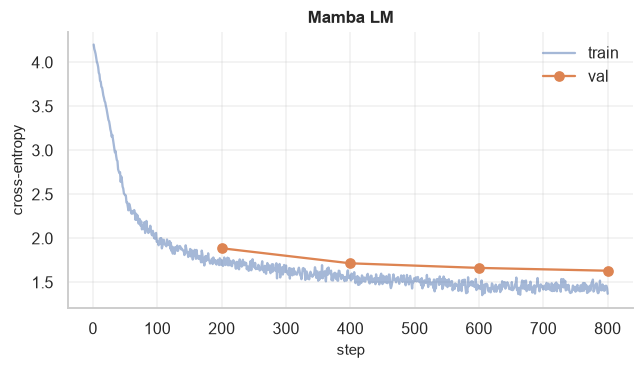


Is mine on the capt as supply the flamed of this is mind help he had she shines.

MENENIUS:
Ah, here to best bloody feel'd his course trose to him.

BUCKINGHAM:
The didst shall to sound of steems sister,
The sweet in these throning
This name
Than any family.

KING RICHARD II:
So side and sooths,
Whi


In [4]:
d = 96
model = DecoderLM(V, d, [Block(d, MambaBlock(d, d_state=16), SwiGLU(d)) for _ in range(3)])
print(f"{count_params(model):,} params"); _ = show_summary(model, input_data=torch.randint(0, V, (1, 64)), depth=2)
hist = train_lm(model, train, val, steps=STEPS, block_size=64, batch_size=32, lr=3e-3, device=device, eval_every=200)
plot_losses(hist, "Mamba LM"); save_result("09 Mamba (SSM)", model, hist)
start = torch.zeros((1, 1), dtype=torch.long, device=device)
print(data["decode"](generate(model, start, 300, temperature=0.8, top_k=10, block_size=128)[0].tolist()))

# ## Selectivity: where does the step size Δ spike?
# Mean Δ over channels for each character of a sentence. The model changes how fast its state moves depending on the token.

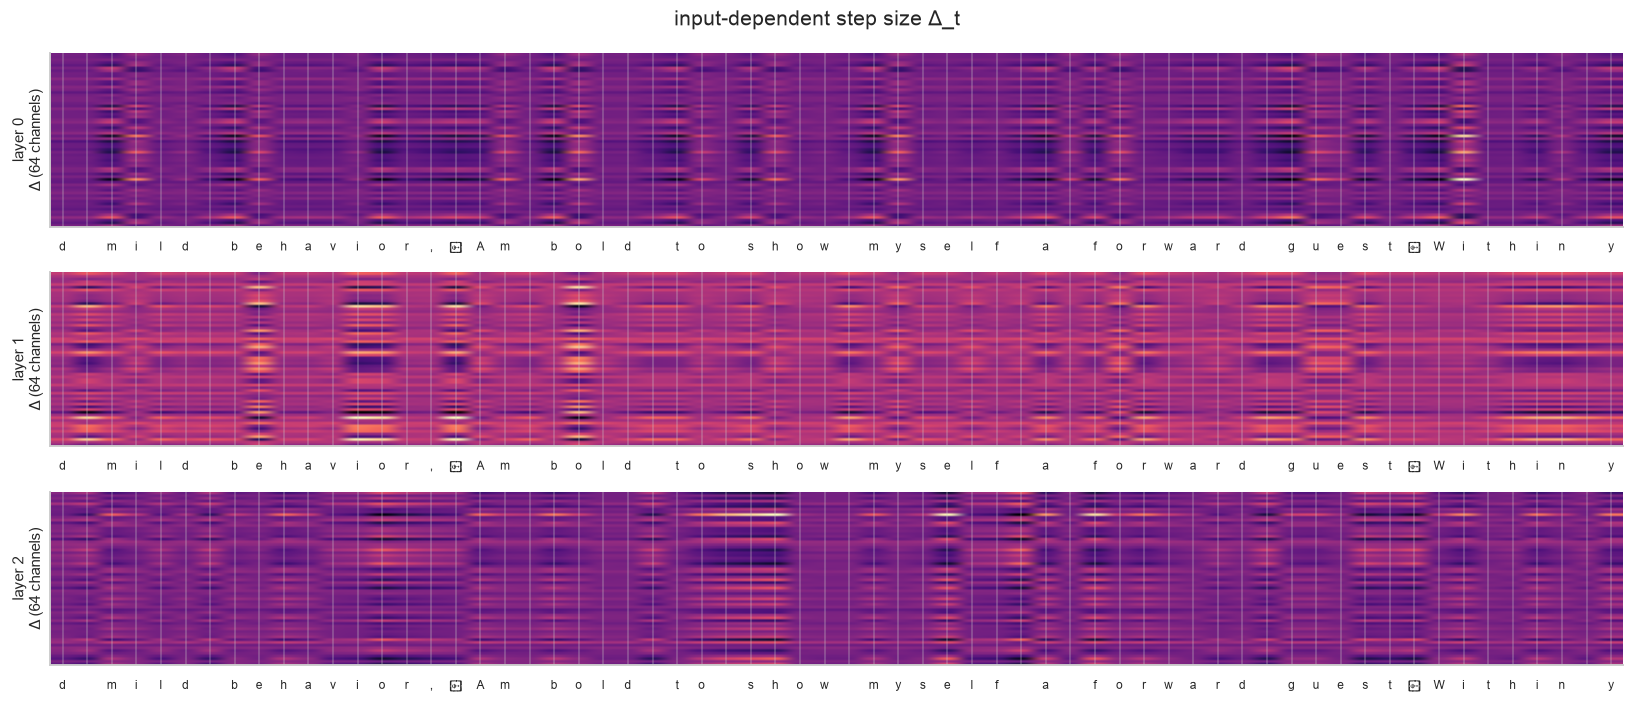

In [5]:
seq = val[500:564]; model.eval(); model(seq[None].to(device)); lab = [("⏎" if c == "\n" else c) for c in data["decode"](seq.tolist())]
fig, axs = plt.subplots(3, 1, figsize=(15, 6.5))
for l, ax in enumerate(axs):
    dt = model.blocks[l].mixer.last_dt[0].cpu()                             # (T, d_inner)
    ax.imshow(dt.T[:64], aspect="auto", cmap="magma"); ax.set_xticks(range(64)); ax.set_xticklabels(lab, fontsize=8); ax.set_yticks([]); ax.set_ylabel(f"layer {l}\nΔ (64 channels)")
plt.suptitle("input-dependent step size Δ_t"); plt.tight_layout(); plt.show()

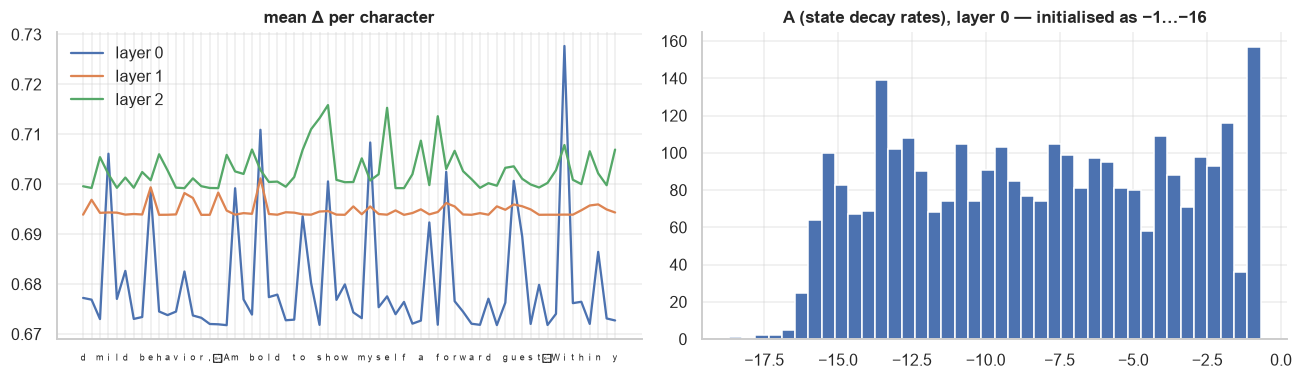

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for l in range(3):
    dtm = model.blocks[l].mixer.last_dt[0].mean(-1).cpu(); ax[0].plot(dtm, label=f"layer {l}")
ax[0].set_xticks(range(64)); ax[0].set_xticklabels(lab, fontsize=6); ax[0].set_title("mean Δ per character"); ax[0].legend()
A = -torch.exp(model.blocks[0].mixer.A_log.detach()).cpu(); ax[1].hist(A.flatten().numpy(), bins=40); ax[1].set_title("A (state decay rates), layer 0 — initialised as −1…−16"); plt.tight_layout(); plt.show()

# ## Memory of the state: how much does the first token still matter?
# We perturb the first character and measure the change of the hidden output at later positions: the SSM state decays
# at input-dependent rates.

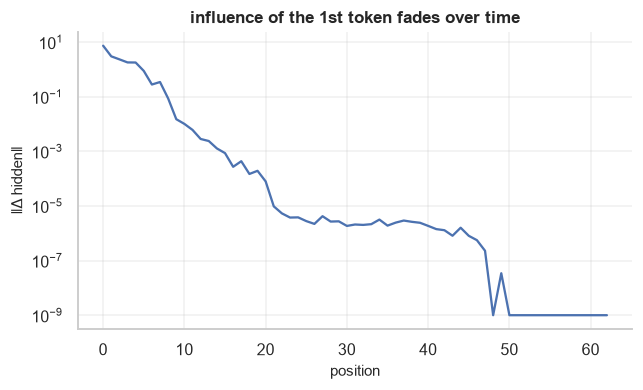

In [7]:
x = val[:64][None].clone().to(device); x2 = x.clone(); x2[0, 0] = (x2[0, 0] + 7) % V
with torch.no_grad():
    def feats(z):
        h = model.tok(z)
        for b in model.blocks: h, _ = b(h)
        return h
    diff = (feats(x) - feats(x2))[0].norm(dim=-1).cpu()
plt.figure(figsize=(6.5, 3.5)); plt.semilogy(diff[1:] + 1e-9); plt.xlabel("position"); plt.ylabel("‖Δ hidden‖"); plt.title("influence of the 1st token fades over time"); plt.grid(alpha=.3, which="both"); plt.show()

# ## Scaling: attention vs SSM at inference
# Attention's per-step cost and memory grow with the context; the SSM's stay constant (state = d_inner × N).

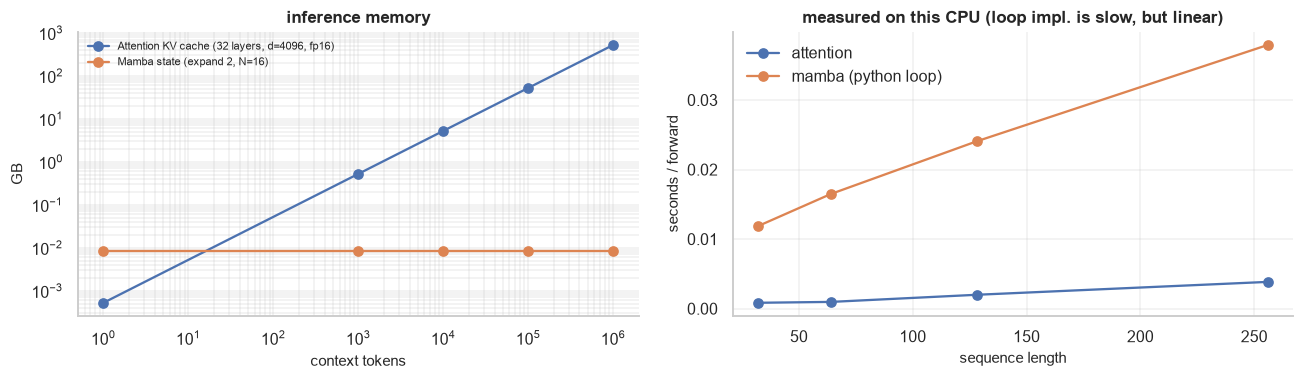

In [8]:
Ts = np.array([1, 1e3, 1e4, 1e5, 1e6]); dm = 4096; N = 16
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].loglog(Ts, Ts * 2 * dm * 2 * 32 / 1e9, "o-", label="Attention KV cache (32 layers, d=4096, fp16)"); ax[0].loglog(Ts, np.full_like(Ts, 2 * dm * N * 2 * 32 / 1e9), "o-", label="Mamba state (expand 2, N=16)")
ax[0].set(xlabel="context tokens", ylabel="GB", title="inference memory"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3, which="both")
tt = {"attention": [], "mamba (python loop)": []}; Tl = [32, 64, 128, 256]
att = Block(96, Attention(96, 4, rope=True), SwiGLU(96)).eval(); mb = Block(96, MambaBlock(96), SwiGLU(96)).eval()
for T in Tl:
    z = torch.randn(4, T, 96)
    for k, blk in [("attention", att), ("mamba (python loop)", mb)]:
        t0 = time.perf_counter(); [blk(z) for _ in range(3)]; tt[k].append((time.perf_counter() - t0) / 3)
for k, v in tt.items(): ax[1].plot(Tl, v, "o-", label=k)
ax[1].set(xlabel="sequence length", ylabel="seconds / forward", title="measured on this CPU (loop impl. is slow, but linear)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

---

## Key takeaways

- Selectivity (input-dependent Δ, B, C) is what lets an SSM choose what to remember.
- The state is constant-size, so memory does not grow with context length.
- Our Python loop is only for clarity: real Mamba uses a fused parallel scan.

## References

- [Gu & Dao, *Mamba* (2023)](https://arxiv.org/abs/2312.00752)
- [Gu et al., *S4* (2021)](https://arxiv.org/abs/2111.00396)
- [Dao & Gu, *Mamba-2 / Transformers are SSMs* (2024)](https://arxiv.org/abs/2405.21060)

---
*← previous: `08_recurrent_rnn_lstm_gru`  ·  next: `10_linear_attention_retnet_rwkv` →*